# Real-vs-fake discriminator: GeoLife Beijing traces

A classifier two-sample test (`docs/realfake/geolife.md`, decision D8): a model is trained to tell
k-point windows of real Beijing traces (label 0) from windows of the synthetic variant
`outings_v2_seed0` (label 1). AUC 0.5 means indistinguishable at this level, 1.0 trivially
detectable. Identifiers, absolute dates and absolute lon/lat never enter the features; train and
test users are disjoint. Results read from `geolife/eval/results/discriminator/` (map features on)
and `discriminator_nomap/`; the SNAP counterpart is `snap/eval/notebooks/viz_discriminator.ipynb`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "geolife").exists())
sys.path.insert(0, str(ROOT / "src"))
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
RES = ROOT / "geolife" / "eval" / "results"
runs = {"map on": RES / "discriminator", "no map": RES / "discriminator_nomap"}
summ = {k: pd.read_csv(d / "discriminator_summary.csv") for k, d in runs.items()}
imp  = {k: pd.read_csv(d / "discriminator_importance.csv") for k, d in runs.items()}
size = {k: pd.read_csv(d / "discriminator_by_size.csv") for k, d in runs.items()}

## 1. Headline: can a classifier tell the traces apart?

Mean test AUC over the 3 user-disjoint folds, against the two controls that make the number
trustworthy: the real-vs-real AUC (one half of the real users against the other; must sit near 0.5)
and the label-permutation AUC (same folds, shuffled training labels).

,run,model,auc,auc_std,ci_lo,ci_hi,permuted,real_vs_real
0,map on,logreg,0.9417,0.0055,0.9322,0.9511,0.4808,0.5227
1,map on,gbm,0.9970,0.0016,0.9955,0.9981,0.4701,0.4841
2,no map,logreg,0.9297,0.0079,0.9185,0.9402,0.4787,0.5325
3,no map,gbm,0.9970,0.0017,0.9955,0.9981,0.4714,0.4723


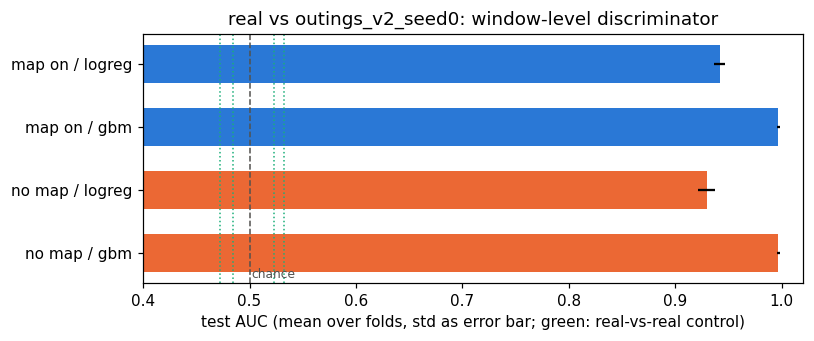

In [2]:
rows = []
for k, s in summ.items():
    m = s[s.method != "real_vs_real"]
    for _, r in m.iterrows():
        rows.append({"run": k, "model": r["model"], "auc": r["auc_mean"], "auc_std": r["auc_std"],
                     "ci_lo": r["auc_lo_mean"], "ci_hi": r["auc_hi_mean"],
                     "permuted": r["permuted_auc_mean"], "real_vs_real": r["real_vs_real_auc_mean"]})
hl = pd.DataFrame(rows)
display(hl.round(4))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(hl))
ax.barh(y, hl["auc"], xerr=hl["auc_std"], color=["#2a78d6" if r == "map on" else "#eb6834" for r in hl["run"]], height=0.6)
ax.set_yticks(y); ax.set_yticklabels(hl["run"] + " / " + hl["model"]); ax.invert_yaxis()
ax.axvline(0.5, color="#52514e", lw=1, ls="--"); ax.text(0.502, len(hl) - 0.6, "chance", fontsize=8, color="#52514e")
for ctrl in hl["real_vs_real"].unique():
    ax.axvline(ctrl, color="#1baf7a", lw=1, ls=":")
ax.set_xlim(0.4, 1.02); ax.set_xlabel("test AUC (mean over folds, std as error bar; green: real-vs-real control)")
ax.set_title("real vs outings_v2_seed0: window-level discriminator")
plt.tight_layout()

**What we see (2026-11-03, after the dt-texture artifact round, realfake D10).** Controls are
clean (real-vs-real 0.47-0.53, permuted 0.46-0.49). Against them: gbm AUC 0.9970 with map features
and 0.9970 without, logreg 0.942/0.930. Before the dt round (first run, same day) this was gbm
0.9996/0.9995 and logreg 0.983/0.981: releasing the dt-run tables (`sensor_dt_runlen`,
`sensor_dt_runlen_user`) and rendering dt as a per-user locked process removed most of the
linearly-visible signal (logreg -0.05) but the boosted model still finds the residual, redundant
texture. The map group remains irrelevant either way - the separation is in the traces themselves,
as on SNAP (gbm 0.9994-0.9999 there).

## 2. Which feature groups carry the separation

Grouped permutation importance (all columns of a group shuffled together, 5 repeats, fold 0,
strongest model): AUC drop when the group is destroyed.

run,map on,no map
group,,
kinematics,0.1120,0.1239
map,0.0022,NaN
sampling,0.1991,0.2250
shape,0.0046,0.0050
stops,0.0006,0.0004
time,-0.0001,-0.0002


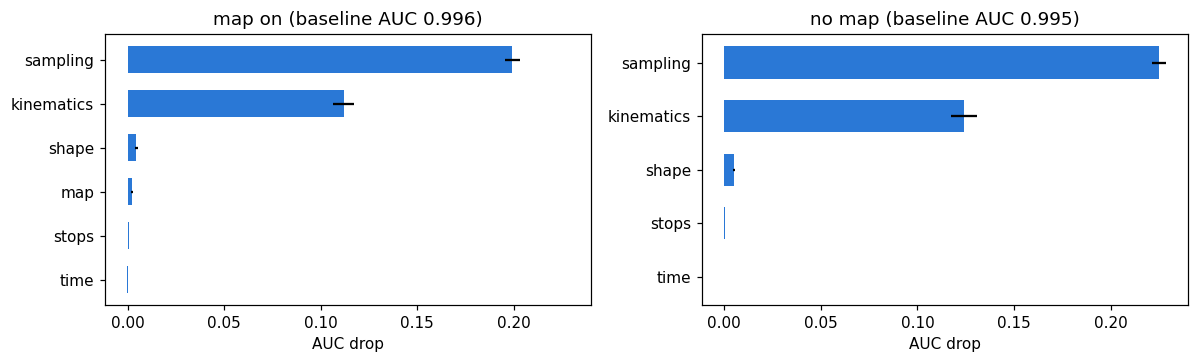

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, (k, df) in zip(axes, imp.items()):
    d = df.sort_values("auc_drop", ascending=True)
    ax.barh(d["group"], d["auc_drop"], xerr=d.get("auc_drop_std"), color="#2a78d6", height=0.6)
    ax.set_title(f"{k} (baseline AUC {d['auc_baseline'].iloc[0]:.3f})"); ax.set_xlabel("AUC drop")
plt.tight_layout()
display(pd.concat([df.assign(run=k) for k, df in imp.items()])
        .pivot_table(index="group", columns="run", values="auc_drop").round(4))

**What we see.** `sampling` still leads but fell with the dt round (drop 0.199 with map /
0.225 without; was 0.258 / 0.266), while `kinematics` roughly doubled in relative weight (0.112 /
0.124; was 0.058 / 0.061) - with the dt texture largely matched, the model shifts onto the speed
regime. `shape`, `stops`, `time` and `map` stay <= 0.005. The grouped drops do not add up to
AUC-0.5: the signal is redundant across groups (destroying one still leaves the others enough).

## 3. AUC by window size

Smaller windows carry less evidence; if the AUC stayed high at k=30 the tell would be per-point, if
it only emerged at k=600 it would be a long-range property.

,run,lo,hi,n,auc
0,map on,30.0,60.0,562,0.990
1,map on,60.0,120.0,483,0.994
2,map on,120.0,240.0,432,0.998
3,map on,240.0,480.0,417,0.999
4,map on,480.0,601.0,114,1.000
0,no map,30.0,60.0,562,0.989
1,no map,60.0,120.0,483,0.995
2,no map,120.0,240.0,432,0.997
3,no map,240.0,480.0,417,0.999
4,no map,480.0,601.0,114,0.999


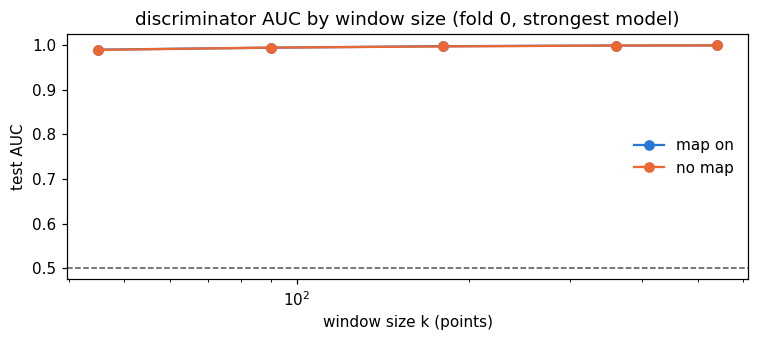

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for (k, df), c in zip(size.items(), ["#2a78d6", "#eb6834"]):
    mid = (df["lo"] + df["hi"]) / 2
    ax.plot(mid, df["auc"], "o-", color=c, label=k)
ax.set_xscale("log"); ax.axhline(0.5, color="#52514e", lw=1, ls="--")
ax.set_xlabel("window size k (points)"); ax.set_ylabel("test AUC"); ax.legend(frameon=False)
ax.set_title("discriminator AUC by window size (fold 0, strongest model)")
plt.tight_layout()
display(pd.concat([df.assign(run=k) for k, df in size.items()])[["run", "lo", "hi", "n", "auc"]].round(3))

**What we see.** Detection is still near-certain even for the smallest windows (AUC ~0.99 at
k 30-60, rising to ~1.0 above; before the dt round: 0.997-1.000): the tell remains local, per-step
texture, not a long-range trajectory property - consistent with the sampling/kinematics
importance.

## 4. Per-feature separators

The committed tables stop at group level. Here the per-feature view, computed once on a fresh
dataset (same loaders, sampler and featurizer as the run; 2000 windows per class, map features
included, user-disjoint split):

* **single-feature AUC**: each feature alone as a ranking score (flipped to >= 0.5), on the test
  windows - "how far does this one number get you";
* **per-feature permutation importance**: AUC drop of the fitted gbm when one feature is shuffled -
  "what does the model actually lean on" (small drops everywhere = redundant signal, as on SNAP).

In [5]:
from geolife.eval.discriminator import (SPEED_DISTANCE_FEATURES, FeatureSubset, TraceFeaturizer,
                                        WindowSampler, load_real_arrays, load_synthetic_arrays)
from geolife.eval.discriminate import road_cells
from realfake.dataset import build_dataset
from realfake.importance import permutation_importance
from realfake.metrics import auc
from realfake.models import MODELS
from realfake.split import group_split

real = load_real_arrays(ROOT / "geolife/inside/data/points.parquet")
fake = load_synthetic_arrays(ROOT / "geolife/outside/synthetic/outings_v2_seed0")
places = pd.read_parquet(ROOT / "geolife/outside/cache/places_beijing_big.parquet")
cells = road_cells(ROOT / "geolife/outside/cache")
feat = TraceFeaturizer(places_latlon=places[["lat", "lon"]].to_numpy(), road_cells=cells)
ds = build_dataset(real, [("seed0", fake)], WindowSampler(), feat, n=2000, seed=0)
train, test = group_split(ds.groups, test_frac=0.25, seed=0, y=ds.y)
gbm = MODELS["gbm"](ds.x[train], ds.y[train], seed=0)
print(f"dataset {ds.x.shape}, test AUC {auc(gbm.scores(ds.x[test]), ds.y[test]):.4f}")

dataset (4000, 67), test AUC 0.9955


,single_auc,perm_drop
feature,,
kinematics:thin30_speed_log_std,0.7655,0.0014
kinematics:raw_speed_log_std,0.7528,0.0011
kinematics:thin30_step_q90,0.7496,0.0001
kinematics:raw_speed_q90,0.7487,0.0002
kinematics:thin30_accel_abs_q90,0.7217,0.0001
kinematics:thin30_speed_q90,0.7210,0.0001
sampling:dt_log_std,0.7079,0.0008
kinematics:raw_speed_q75,0.7072,0.0000
kinematics:raw_step_q90,0.7045,-0.0001


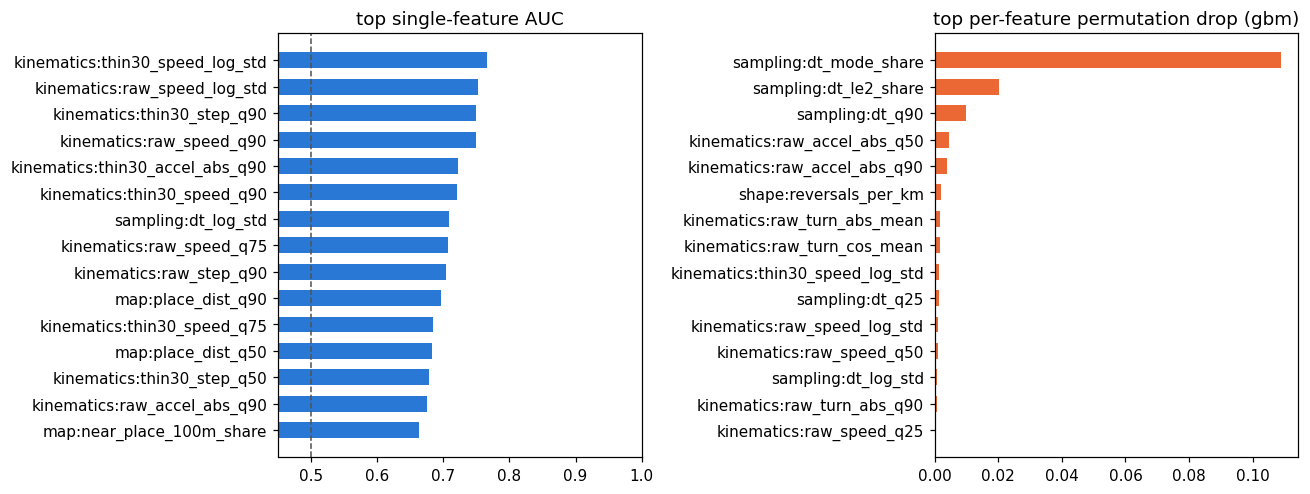

In [6]:
xt, yt = ds.x[test], ds.y[test]
uni = np.array([max(a := auc(xt[:, j], yt), 1 - a) for j in range(xt.shape[1])])
per = permutation_importance(gbm, xt, yt, ds.feature_names, {f: [f] for f in ds.feature_names}, seed=0)
per = per.rename(columns={"group": "feature"}).set_index("feature")
tab = pd.DataFrame({"feature": ds.feature_names, "single_auc": uni}).set_index("feature")
tab["perm_drop"] = per["auc_drop"]
tab = tab.sort_values("single_auc", ascending=False)
display(tab.head(20).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
top = tab.head(15).iloc[::-1]
axes[0].barh(top.index, top["single_auc"], color="#2a78d6", height=0.6)
axes[0].axvline(0.5, color="#52514e", lw=1, ls="--"); axes[0].set_xlim(0.45, 1.0)
axes[0].set_title("top single-feature AUC")
topp = tab.sort_values("perm_drop", ascending=False).head(15).iloc[::-1]
axes[1].barh(topp.index, topp["perm_drop"], color="#eb6834", height=0.6)
axes[1].set_title("top per-feature permutation drop (gbm)")
plt.tight_layout()

## 5. How the top separators differ

ECDFs of the strongest single features, real (black) vs synthetic (orange), over the test windows -
the direction of each gap says what the generator should fix.

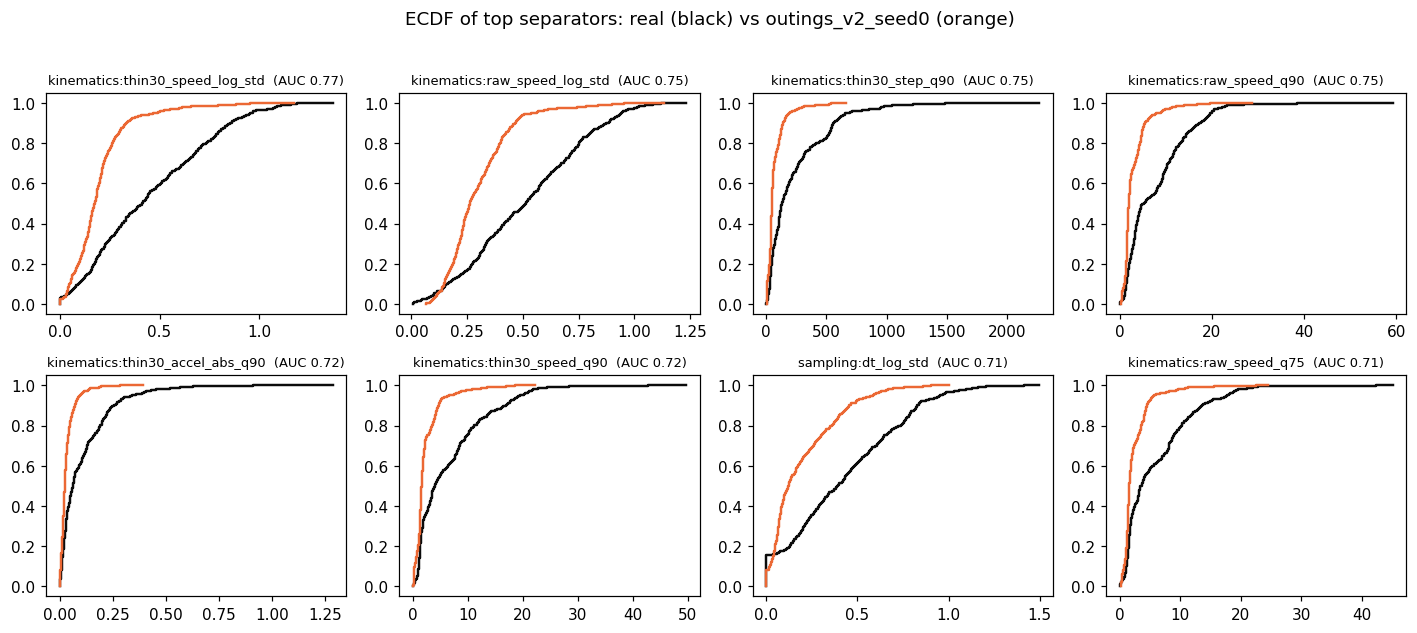

In [7]:
top8 = tab.head(8).index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
for ax, f in zip(axes.ravel(), top8):
    j = ds.feature_names.index(f)
    for lab, c in ((0, "#0b0b0b"), (1, "#eb6834")):
        v = np.sort(xt[yt == lab, j])
        ax.step(v, np.linspace(0, 1, len(v)), color=c, lw=1.6)
    ax.set_title(f"{f}  (AUC {tab.loc[f, 'single_auc']:.2f})", fontsize=8.5)
fig.suptitle("ECDF of top separators: real (black) vs outings_v2_seed0 (orange)", y=1.02)
plt.tight_layout()

**What we see (the separator list, 2026-11-03, after the dt round).** Two findings:

1. **The best single separators are now ALL kinematics - the synthetic traces are too SLOW and too
   uniform.** Top single-feature AUCs: `thin30_speed_log_std` (0.77; real window-median 0.41 vs
   synthetic 0.18), `raw_speed_log_std` (0.75), `thin30_step_q90` (0.75; 131 m vs 48 m),
   `raw_speed_q90` (0.75; 5.2 vs 2.0 m/s). This is the overcorrection of the old baseline (2.7x too
   FAST at 13.5 m/s): this seed's `sensor_speed` table fell below its usability floor, so rendering
   pinned speeds near default medians and lost both the fast tail and the within-outing spread.
   This is the next generator item - and it needs a passing `sensor_speed` seed or a better speed
   fit, not hand-tuning.
2. **The residual dt signal is small but the model still uses it.** `sampling:dt_mode_share` keeps
   the top permutation drop (0.112) though its single AUC fell 0.80 -> 0.64 with the dt-run tables
   (section 6): what remains is the slight modal-share overshoot of the single-step-excursion
   model (0.92 vs real 0.84), `dt_le2_share` (0.019 drop; real base interval p50 2 s vs synthetic
   3 s) and the still-missing within-run pause tail (`dt_q90` 0.014; real dt p99 ~137 s vs ~25 s -
   gap placement, D26 semantics). Kinematics per-feature drops stay ~0 despite single AUCs of
   0.7-0.77: the signal is redundant (the SNAP pattern) - which is why gbm barely moved (0.9996 ->
   0.9970) while linear logreg fell 0.983 -> 0.93-0.94.

`map:place_dist_*` separates alone but the model never needs it - consistent with the near-zero map
group drop in section 2.

## 6. EDA: the dt texture, real against fake

The discriminator's strongest lever was the sampling-interval SEQUENCE, so here it is directly:
400 fresh windows per side (same sampler as the dataset). Four views: the pooled dt distribution,
example per-window dt sequences, per-window lock statistics (modal-dt share, lag-1 repeat rate), and
the probability that the next step keeps the same dt. Since the dt round, the texture is driven by
two released tables - `sensor_dt_runlen` (pooled run-length pmf) and `sensor_dt_runlen_user` (the
user's mean run length, one-hot) - rendered as a home interval held for geometric runs with
single-step excursions (realfake D10).

In [8]:
ws = WindowSampler()
rng2 = np.random.default_rng(7)
rwin = [ws(real, rng2).payload for _ in range(400)]
fwin = [ws(fake, rng2).payload for _ in range(400)]

def dt_stats(wins):
    mode_share, persist = [], []
    for w in wins:
        r = np.rint(np.diff(w.t).astype(float))
        _, cnt = np.unique(r, return_counts=True)
        mode_share.append(cnt.max() / len(r))
        persist.append(float(np.mean(r[1:] == r[:-1])) if len(r) > 1 else 0.0)
    return np.asarray(mode_share), np.asarray(persist)

rms, rpe = dt_stats(rwin); fms, fpe = dt_stats(fwin)
rdt = np.concatenate([np.diff(w.t) for w in rwin]).astype(float)
fdt = np.concatenate([np.diff(w.t) for w in fwin]).astype(float)
display(pd.DataFrame({
    "real": {"modal-dt share p50": np.median(rms), "lag-1 repeat p50": np.median(rpe),
             "pooled dt p50": np.median(rdt), "dt p90": np.percentile(rdt, 90), "dt p99": np.percentile(rdt, 99)},
    "fake": {"modal-dt share p50": np.median(fms), "lag-1 repeat p50": np.median(fpe),
             "pooled dt p50": np.median(fdt), "dt p90": np.percentile(fdt, 90), "dt p99": np.percentile(fdt, 99)},
}).round(3))

,real,fake
modal-dt share p50,0.841,0.924
lag-1 repeat p50,0.836,0.847
pooled dt p50,2.000,3.000
dt p90,10.000,17.000
dt p99,136.700,25.000


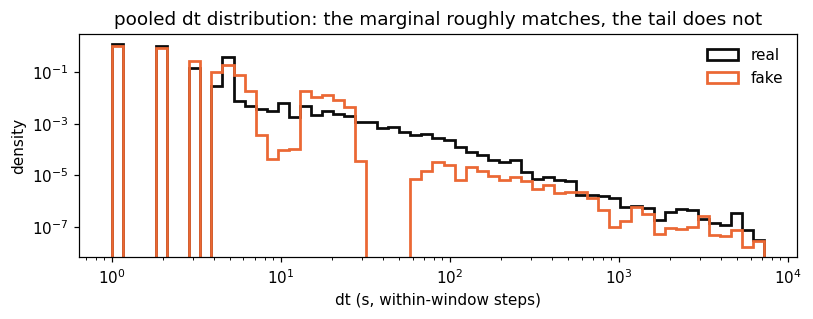

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3))
bins = np.logspace(0, np.log10(7200), 60)
for dt, c, lab in ((rdt, "#0b0b0b", "real"), (fdt, "#eb6834", "fake")):
    ax.hist(dt, bins=bins, density=True, histtype="step", lw=1.8, color=c, label=lab)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("dt (s, within-window steps)"); ax.set_ylabel("density")
ax.set_title("pooled dt distribution: the marginal roughly matches, the tail does not")
ax.legend(frameon=False); plt.tight_layout()

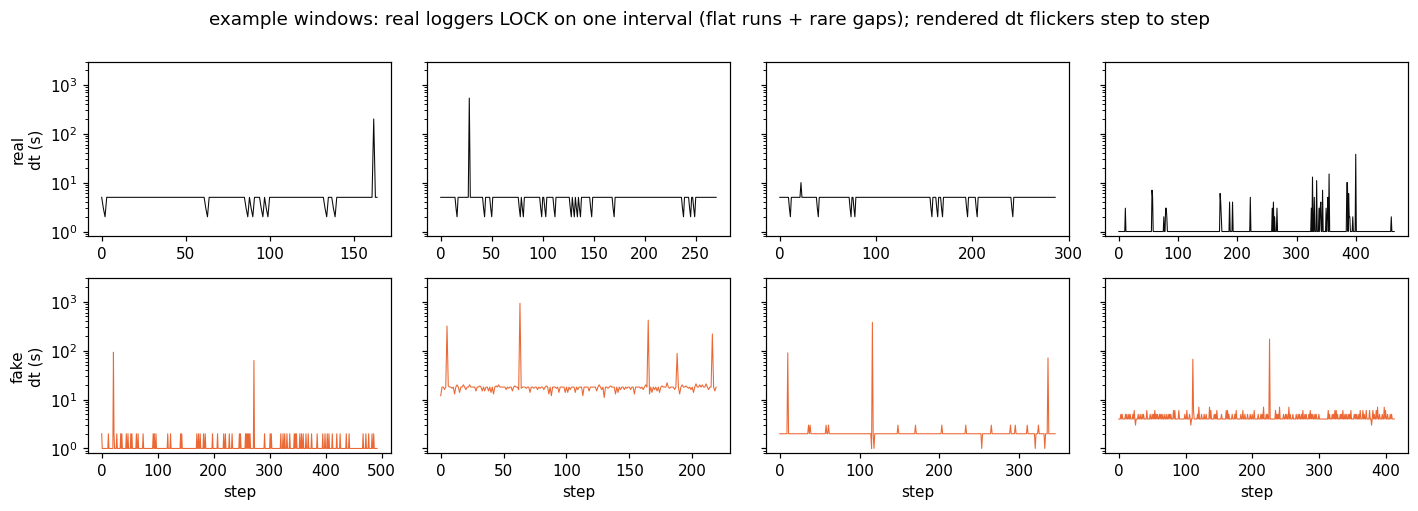

In [10]:
rng3 = np.random.default_rng(1)
def pick(wins, n=4, kmin=150):
    big = [w for w in wins if w.k >= kmin]
    return [big[i] for i in rng3.choice(len(big), n, replace=False)]
fig, axes = plt.subplots(2, 4, figsize=(13, 4.6), sharey=True)
for row, (wins, c, lab) in enumerate(((pick(rwin), "#0b0b0b", "real"), (pick(fwin), "#eb6834", "fake"))):
    for ax, w in zip(axes[row], wins):
        dt = np.diff(w.t).astype(float)
        ax.plot(dt, color=c, lw=0.7)
        ax.set_yscale("log"); ax.set_ylim(0.8, 3000)
        if ax is axes[row][0]:
            ax.set_ylabel(f"{lab}\ndt (s)")
for ax in axes[1]:
    ax.set_xlabel("step")
fig.suptitle("example windows: real loggers LOCK on one interval (flat runs + rare gaps); "
             "rendered dt flickers step to step", y=1.0)
plt.tight_layout()

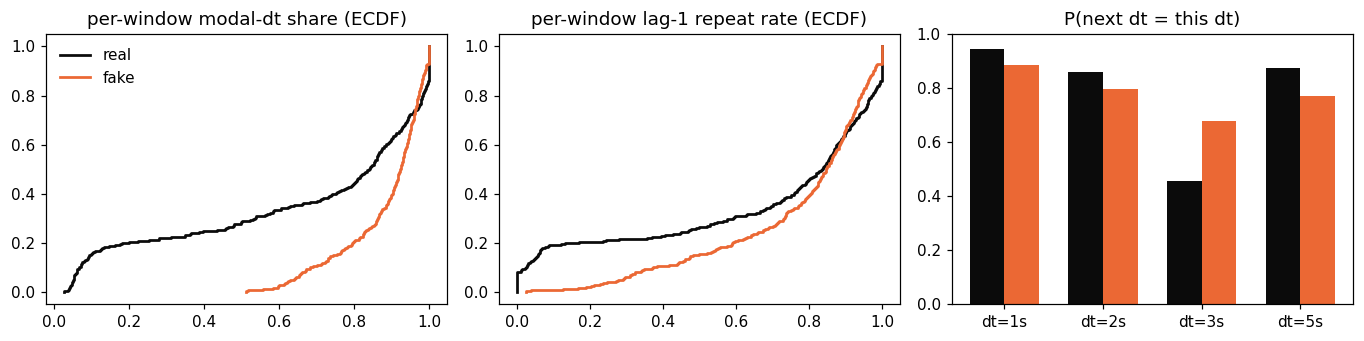

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.2))
for vals, c, lab in ((rms, "#0b0b0b", "real"), (fms, "#eb6834", "fake")):
    axes[0].step(np.sort(vals), np.linspace(0, 1, len(vals)), color=c, lw=1.8, label=lab)
axes[0].set_title("per-window modal-dt share (ECDF)"); axes[0].legend(frameon=False)
for vals, c in ((rpe, "#0b0b0b"), (fpe, "#eb6834")):
    axes[1].step(np.sort(vals), np.linspace(0, 1, len(vals)), color=c, lw=1.8)
axes[1].set_title("per-window lag-1 repeat rate (ECDF)")
vs = (1, 2, 3, 5)
width = 0.35
for off, (wins, c, lab) in ((-width/2, (rwin, "#0b0b0b", "real")), (width/2, (fwin, "#eb6834", "fake"))):
    a = np.concatenate([np.rint(np.diff(w.t))[:-1] for w in wins])
    b = np.concatenate([np.rint(np.diff(w.t))[1:] for w in wins])
    p = [np.mean(b[a == v] == v) if np.sum(a == v) > 100 else np.nan for v in vs]
    axes[2].bar(np.arange(len(vs)) + off, p, width, color=c, label=lab)
axes[2].set_xticks(range(len(vs))); axes[2].set_xticklabels([f"dt={v}s" for v in vs])
axes[2].set_title("P(next dt = this dt)"); axes[2].set_ylim(0, 1)
plt.tight_layout()

**What we see (after the dt round).** REAL loggers lock on one interval - flat runs of
identical dt, modal-dt share p50 0.84, lag-1 repeat p50 0.84 - interrupted by brief excursions and
rare long pauses. The synthetic windows now show the same locked texture, driven by the released
tables: lag-1 repeat p50 0.84-0.85 across window draws (real 0.836) and modal share 0.92 (real 0.84; the single-step
excursion model is slightly too home-bound). How we got there, all on released statistics:

| renderer | modal share p50 | lag-1 repeat p50 |
|---|---|---|
| before: per-step draw around the user's interval | 0.55 | 0.35 |
| pooled `sensor_dt_runlen`, runs merge | 1.00 | 1.00 |
| + maximal-run semantics (run end changes dt) | 1.00 | 1.00 |
| + per-user regime `sensor_dt_runlen_user` (median) | 0.48 | 0.65 |
| + regime = user's MEAN run length (repeat = 1 - 1/mean) | 0.51 | 0.83 |
| + home interval with single-step excursions | **0.92** | **0.84** |
| real | 0.84 | 0.84 |

What is still off: the base interval itself (real dt p50 2 s, synthetic 3 s - the per-user interval
table's median bin) and the in-run pause tail (pooled within-window dt p99 ~137 s real vs ~25 s
synthetic: rendered gaps rarely land inside sampled windows; cause not yet diagnosed).

## 7. Without speed and distance features

Speed and distance are not part of what this generator round models, so a classifier that wins on
them says nothing about the modelled regime. Same data, sampler, folds and controls; the featurizer
is wrapped in `FeatureSubset(..., SPEED_DISTANCE_FEATURES)` (`--no-speed-distance`), which drops:
step lengths, speeds and accelerations (raw and 30 s-thinned), reversals per km, the slow-point
shares and the stop jitter in metres, and the map distances to places. Kept: heading/turn angles,
scale-free shape ratios (tortuosity, extent over path, anisotropy), stay counts and dwell shares,
all sampling features, local time, and the on-road shares. Results:
`geolife/eval/results/discriminator_nospeed{,_nomap}/`.

In [12]:
runs_ns = {"map on": RES / "discriminator_nospeed", "no map": RES / "discriminator_nospeed_nomap"}
summ_ns = {k: pd.read_csv(d / "discriminator_summary.csv") for k, d in runs_ns.items()}
imp_ns  = {k: pd.read_csv(d / "discriminator_importance.csv") for k, d in runs_ns.items()}
size_ns = {k: pd.read_csv(d / "discriminator_by_size.csv") for k, d in runs_ns.items()}
rows = []
for label, sm in (("all features", summ), ("no speed/distance", summ_ns)):
    for k, s in sm.items():
        for _, r in s[s.method != "real_vs_real"].iterrows():
            rows.append({"features": label, "run": k, "model": r["model"], "auc": r["auc_mean"],
                         "auc_std": r["auc_std"], "permuted": r["permuted_auc_mean"],
                         "real_vs_real": r["real_vs_real_auc_mean"]})
display(pd.DataFrame(rows).round(4))
display(pd.concat([df.assign(run=k) for k, df in imp_ns.items()])
        .pivot_table(index="group", columns="run", values="auc_drop").round(4))
display(pd.concat([df.assign(run=k) for k, df in size_ns.items()])[["run", "lo", "hi", "n", "auc"]].round(3))

,features,run,model,auc,auc_std,permuted,real_vs_real
0,all features,map on,logreg,0.9417,0.0055,0.4808,0.5227
1,all features,map on,gbm,0.9970,0.0016,0.4701,0.4841
2,all features,no map,logreg,0.9297,0.0079,0.4787,0.5325
3,all features,no map,gbm,0.9970,0.0017,0.4714,0.4723
4,no speed/distance,map on,logreg,0.8916,0.0050,0.4934,0.5210
5,no speed/distance,map on,gbm,0.9902,0.0043,0.4622,0.4666
6,no speed/distance,no map,logreg,0.8927,0.0050,0.4936,0.5207
7,no speed/distance,no map,gbm,0.9902,0.0045,0.4560,0.4734


run,map on,no map
group,,
kinematics,0.0657,0.0667
map,0.0000,NaN
sampling,0.3603,0.3563
shape,0.0057,0.0061
stops,0.0004,0.0003
time,0.0003,0.0004


,run,lo,hi,n,auc
0,map on,30.0,60.0,562,0.974
1,map on,60.0,120.0,483,0.986
2,map on,120.0,240.0,432,0.992
3,map on,240.0,480.0,417,0.994
4,map on,480.0,601.0,114,0.986
0,no map,30.0,60.0,562,0.974
1,no map,60.0,120.0,483,0.985
2,no map,120.0,240.0,432,0.992
3,no map,240.0,480.0,417,0.993
4,no map,480.0,601.0,114,0.985


In [13]:
feat_ns = FeatureSubset(TraceFeaturizer(include_map=False), SPEED_DISTANCE_FEATURES)
ds_ns = build_dataset(real, [("seed0", fake)], WindowSampler(), feat_ns, n=2000, seed=0)
tr_ns, te_ns = group_split(ds_ns.groups, test_frac=0.25, seed=0, y=ds_ns.y)
gbm_ns = MODELS["gbm"](ds_ns.x[tr_ns], ds_ns.y[tr_ns], seed=0)
xt2, yt2 = ds_ns.x[te_ns], ds_ns.y[te_ns]
print(f"no-speed/distance dataset {ds_ns.x.shape}, test AUC {auc(gbm_ns.scores(xt2), yt2):.4f}")
uni2 = np.array([max(a := auc(xt2[:, j], yt2), 1 - a) for j in range(xt2.shape[1])])
per2 = permutation_importance(gbm_ns, xt2, yt2, ds_ns.feature_names, {f: [f] for f in ds_ns.feature_names}, seed=0)
tab2 = pd.DataFrame({"feature": ds_ns.feature_names, "single_auc": uni2}).set_index("feature")
tab2["perm_drop"] = per2.rename(columns={"group": "feature"}).set_index("feature")["auc_drop"]
tab2["real_p50"] = [np.median(xt2[yt2 == 0, j]) for j in range(xt2.shape[1])]
tab2["fake_p50"] = [np.median(xt2[yt2 == 1, j]) for j in range(xt2.shape[1])]
display(tab2.sort_values("perm_drop", ascending=False).head(12).round(4))
display(tab2.sort_values("single_auc", ascending=False).head(12).round(4))

no-speed/distance dataset (4000, 36), test AUC 0.9846


,single_auc,perm_drop,real_p50,fake_p50
feature,,,,
sampling:dt_mode_share,0.6395,0.1655,0.8434,0.9357
sampling:dt_le2_share,0.5992,0.0650,0.1724,0.0124
sampling:dt_log_std,0.7079,0.0301,0.3933,0.1216
sampling:dt_q90,0.5674,0.0283,5.0000,3.0000
kinematics:raw_turn_cos_mean,0.6284,0.0197,0.9011,0.7663
kinematics:raw_turn_abs_mean,0.5322,0.0110,13.6684,10.5682
sampling:dt_q25,0.5157,0.0105,3.0000,3.0000
kinematics:raw_turn_abs_q90,0.5255,0.0104,29.5270,17.6822
sampling:dt_gt60_share,0.6218,0.0060,0.0036,0.0000


,single_auc,perm_drop,real_p50,fake_p50
feature,,,,
sampling:dt_log_std,0.7079,0.0301,0.3933,0.1216
sampling:dt_mode_share,0.6395,0.1655,0.8434,0.9357
kinematics:raw_turn_cos_mean,0.6284,0.0197,0.9011,0.7663
sampling:dt_gt60_share,0.6218,0.0060,0.0036,0.0000
kinematics:thin30_turn_abs_mean,0.6139,0.0005,32.2370,16.1031
kinematics:thin30_turn_abs_q90,0.6134,0.0001,75.8110,42.5555
time:weekend_share,0.6093,0.0003,0.0000,0.0000
sampling:dt_le2_share,0.5992,0.0650,0.1724,0.0124
sampling:dt_gt300_share,0.5924,0.0005,0.0000,0.0000


**What we see.** Removing speed and distance (24 features; 29 with the map distances) lowers
the headline but does not close it: gbm AUC 0.990 (was 0.997 with all features), logreg 0.892 (was
0.93-0.94); controls clean (real-vs-real 0.47-0.52, permuted 0.46-0.49). The map group is now worth
nothing at all, so the two runs agree. Short windows still separate (AUC 0.974 at 30-60 points).

What the model uses now is almost entirely the **dt process** - which IS in scope of this round:

- `sampling` group drop 0.36 (it was 0.20-0.23 with the speed features present to share the load);
- `dt_mode_share` (drop 0.166): window median 0.84 real vs 0.94 synthetic - after the dt round the
  synthetic windows are now slightly TOO locked on the home interval;
- `dt_le2_share` (drop 0.065): share of steps at <= 2 s, 0.17 real vs 0.01 synthetic - the synthetic
  home intervals are too slow (the base-interval gap noted in section 6);
- `dt_log_std` (best single feature, AUC 0.71): 0.39 real vs 0.12 synthetic - real windows mix
  intervals far more; `dt_q90` 5 s vs 3 s and `dt_gt60_share` (real windows contain >60 s pauses,
  synthetic ones essentially never) say the same: no long excursions or pauses inside runs.

The second, much smaller signal is **heading** (`kinematics` now = turn angles only, drop 0.066):
raw lag-1 heading correlation 0.90 real vs 0.77 synthetic (rendered headings wobble more step to step)
and, at the 30 s scale, mean turn 32 deg real vs 16 deg synthetic (synthetic paths are straighter).
If heading is also outside this round's model, `--exclude 'kinematics:*'` removes it; the dt items
above stay the main lever either way.

Next for the generator, all through released tables: (1) the per-user interval - more mass at 1-2 s;
(2) excursion variety - excursions longer than one step and to more than one value, so windows get
real dt spread; (3) pauses inside runs (the >60 s gaps that real windows contain).

## 8. Pointers

Full tables: `geolife/eval/results/discriminator{,_nomap,_nospeed,_nospeed_nomap}/discriminator*.{csv,json}`. Design and the
dropped-by-construction list: `docs/realfake/geolife.md` (D8; first result D9, dt round D10). The
first-run tables are in git history (commit 97571a4). SNAP counterpart and its findings:
`docs/realfake/snap.md`, `snap/eval/notebooks/viz_discriminator.ipynb`. Acceptance criteria once the
generator improves: controls near 0.5 first, then AUC toward the real-vs-real floor.